# DH Final SELECTION — 20260722_v2000 (cull -> collapse -> rank)

v3, 2026-08-03. The plan, per Bobby:

For each component stage (**S1 -> S2 -> bulk -> tail**):
1. **Cull horrible** — drop options clearly worse than the best (generous bound;
   only obvious losers die).
2. **Collapse twins** — options within noise of each other on every metric in
   every seed merge into ONE representative: the most parsimonious.

THEN, on the surviving pool (no junk, no clones): **Kendall tau -> prune ->
Borda + TOPSIS** — the composite rank is the decision mechanism, and it works
here precisely because the clones that made ranks meaningless are gone.

Notes: comparisons are per-threshold wherever the metric's estimand depends on
the threshold (S2/bulk/tail); both thresholds ride through to the final rank.
Gaps/twin-distances are in seed-SE units (paired across the 5 shared fold
assignments). Trim ratios join at the tail stage (gate) and the final rank
(metrics). Cross-vintage rule: match configs by CONFIG_COLS, never mid.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
import re
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

from idd_tc_mortality.select.model_selection import (
    CONFIG_COLS, prepare_rankings_df, borda_rank, topsis_rank,
    kendall_tau_heatmap,
)
from idd_tc_mortality.cache import model_id as compute_model_id

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
pd.options.display.max_columns = 80
pd.options.display.width = 200

## Paths

In [2]:
ROOT      = Path('/mnt/team/idd/pub/idd_tc_mortality')
EVAL_DATE = '20260722_v2000_final'
DATA_DATE = '20260722_v2000'

RESULTS_PATH   = ROOT / '02-evaluate' / EVAL_DATE / 'dh_results.parquet'
EVAL_DIR       = ROOT / '02-evaluate' / EVAL_DATE
DATA_PATH      = ROOT / '00-data'     / DATA_DATE / 'input.parquet'
MODEL_PRED_DIR = EVAL_DIR / 'model_predictions'
MANIFEST_PATH  = EVAL_DIR / 'manifest.json'

for pth in (RESULTS_PATH, EVAL_DIR, DATA_PATH, MODEL_PRED_DIR, MANIFEST_PATH):
    assert pth.exists(), f'Missing: {pth}'
print('All paths resolve.')

All paths resolve.


## Load

In [3]:
dh_results = pd.read_parquet(RESULTS_PATH)
data       = pd.read_parquet(DATA_PATH)
obs        = data   # alias used by the prediction loaders

print(f'dh_results : {dh_results.shape[0]:,} rows x {dh_results.shape[1]} cols')
print(f'fold_tags  : {dh_results["fold_tag"].value_counts().to_dict()}')
print(f'configs    : {dh_results.groupby(CONFIG_COLS, dropna=False).ngroups:,} unique')

dh_results : 909,920 rows x 252 cols
fold_tags  : {'insample': 154000, 'oos_seed4': 152240, 'oos_seed0': 151360, 'oos_seed1': 151360, 'oos_seed2': 151360, 'oos_seed3': 149600}
configs    : 154,000 unique


# Gate 0 -- Drop terrible exposure modes

In [4]:
# No exposure-weighted components anywhere: var_weights=exposed degenerates the
# tail distributions (needle fits) and uniformly loses on bulk fit (14-24 seed-SE
# behind at 0.70). S1/S2 never used weights, so this makes the whole model
# weighting-free. Subsumes the gamma IRLS exclusion (its failures were all f+w).
m = ((dh_results['tail_exposure_mode'] == 'free+weight')
     | (dh_results['bulk_exposure_mode'] == 'free+weight'))
print(f'dropping {m.sum():,} rows with any free+weight component '
      f'(tail f+w: {(dh_results["tail_exposure_mode"] == "free+weight").sum():,}, '
      f'bulk f+w: {(dh_results["bulk_exposure_mode"] == "free+weight").sum():,})')
dh_results = dh_results[~m].copy()


dropping 624,800 rows with any free+weight component (tail f+w: 339,680, bulk f+w: 454,960)


## Gate 1 — gamma free+weight exclusion

Undamped gamma IRLS diverges/oscillates on these fits (v2000@0.70: 5/9 cells
dead, 3/9 non-converged rows; convergence not persisted -> wholesale exclusion).
`None` | `'all'` | `[0.70]`.

In [5]:
# Gamma free+weight exclusion — SUBSUMED by the all-components free+weight
# gate above (every gamma IRLS failure was a free+weight cell). Kept as a
# no-op assertion that nothing gamma+f+w survived the gate.
assert ((dh_results['tail_family'] == 'gamma')
        & (dh_results['tail_exposure_mode'] == 'free+weight')).sum() == 0
print('gamma free+weight: 0 rows (subsumed by the f+w gate)')

gamma free+weight: 0 rows (subsumed by the f+w gate)


## Gate 2 — rankings frame, non-finite cull, symmetric calibration gate

In [6]:
df_oos = prepare_rankings_df(dh_results, subset='oos')
print(f'{len(df_oos):,} configs before gates')

oos_numeric = [c for c in df_oos.columns
               if c.endswith('_oos') and pd.api.types.is_numeric_dtype(df_oos[c])]
finite = np.isfinite(df_oos[oos_numeric].to_numpy()).all(axis=1)
df_oos = df_oos[finite].copy()
print(f'{len(df_oos):,} after non-finite cull')

GATE_RATIO = 2.0   # TUNE: keep 1/GATE <= full ratio <= GATE (log-symmetric)
keep = np.abs(np.log(df_oos['full_pred_obs_ratio_oos'])) <= np.log(GATE_RATIO)
df_oos = df_oos[keep].copy()
print(f'{len(df_oos):,} after |log full_pred_obs_ratio| <= log({GATE_RATIO})')

def decode_cov_columns(df):
    for stage in ['s1', 's2', 'bulk', 'tail']:
        col = f'{stage}_cov'
        lut = {s: json.loads(s) for s in df[col].unique()}
        covs = ['basin', 'is_island', 'sdi', 'wind_speed']
        for cov in covs:
            df[f'{stage}_{cov}'] = df[col].map(lambda s: lut[s].get(cov, False))
        df[f'{stage}_pattern'] = df[col].map(
            lambda s: '+'.join(c for c in covs if lut[s].get(c, False)))
    return df

df_oos = decode_cov_columns(df_oos)
for st in ['s1', 's2', 'bulk', 'tail']:
    df_oos[f'_k_{st}'] = (df_oos[f'{st}_pattern'].str.count(r'\+')
                          + (df_oos[f'{st}_pattern'] != '').astype(int))
df_oos['_k_total'] = df_oos[['_k_s1', '_k_s2', '_k_bulk', '_k_tail']].sum(axis=1)
print('cov patterns + term counts attached')

47,520 configs before gates
47,520 after non-finite cull
18,171 after |log full_pred_obs_ratio| <= log(2.0)
cov patterns + term counts attached


## `mid` reconstruction (needed for prediction loading)

In [7]:
manifest = json.loads(MANIFEST_PATH.read_text())

spec_lookup = {}
for cid, spec in manifest.items():
    if not isinstance(spec, dict) or spec.get('fold_tag', 'is') != 'is':
        continue
    key = (spec.get('component'), spec.get('threshold_quantile'), spec.get('family'),
           spec.get('exposure_mode'),
           json.dumps(spec.get('covariate_combo', {}), sort_keys=True))
    spec_lookup[key] = spec

def _row_to_mid(row):
    q = row['threshold_quantile']
    s1 = spec_lookup[('s1',   None, row['s1_family'],   row['s1_exposure_mode'],   row['s1_cov'])]
    s2 = spec_lookup[('s2',   q,    row['s2_family'],   row['s2_exposure_mode'],   row['s2_cov'])]
    bk = spec_lookup[('bulk', q,    row['bulk_family'], row['bulk_exposure_mode'], row['bulk_cov'])]
    tl = spec_lookup[('tail', q,    row['tail_family'], row['tail_exposure_mode'], row['tail_cov'])]
    return compute_model_id(s1, s2, bk, tl)

df_oos['mid'] = df_oos.apply(_row_to_mid, axis=1)
print(f'mid attached: {df_oos["mid"].nunique():,} unique')

mid attached: 18,171 unique


## Prediction index + loader (shards only; flat root resolved lazily)

Needed at the tail stage (trim gate) and the final ranking (trim metrics).
Never readdir the flat root (leaked tmp churn; ~650 entries/s measured).

In [8]:
_PRED_RE = re.compile(r'^([0-9a-f]{32})(?:_(.+))?_predictions\.parquet$')
FOLD_TAGS = ['insample'] + [f'oos_seed{i}' for i in range(5)]

def build_pred_index(model_pred_dir, workers=24):
    """Threaded shard scan: NFS metadata latency overlaps across directories."""
    import time
    from concurrent.futures import ThreadPoolExecutor
    t0 = time.time()
    shards = sorted(str(p) for p in Path(model_pred_dir).glob('task_*'))

    def scan(shard):
        out = []
        for e in os.scandir(shard):
            m = _PRED_RE.match(e.name)
            if m:
                out.append((m.group(1), m.group(2), e.path))
        return out

    idx, n = {}, 0
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for i, res in enumerate(pool.map(scan, shards)):
            for mid, tag, path in res:
                idx.setdefault(mid, {})[tag] = path
            n += len(res)
            if (i + 1) % 40 == 0:
                print(f'  shard {i+1}/{len(shards)}: {n:,} files ({time.time()-t0:.0f}s)', flush=True)
    print(f'  {n:,} files across {len(shards)} shards in {time.time()-t0:.0f}s')
    return idx

PRED_INDEX = build_pred_index(MODEL_PRED_DIR)

def _resolve_flat(mid):
    files = {}
    b = MODEL_PRED_DIR / f'{mid}_predictions.parquet'
    if b.exists():
        files[None] = str(b)
    else:
        for tag in FOLD_TAGS:
            p = MODEL_PRED_DIR / f'{mid}_{tag}_predictions.parquet'
            if p.exists():
                files[tag] = str(p)
    if not files:
        raise FileNotFoundError(f'no predictions for {mid}')
    PRED_INDEX[mid] = files
    return files

def load_pred_frames(mid):
    files = PRED_INDEX.get(mid) or _resolve_flat(mid)
    if None in files:
        stacked = pd.read_parquet(files[None])
        groups = {t: g.reset_index(drop=True)
                  for t, g in stacked.groupby('fold_tag', sort=False)}
    else:
        groups = {t: pd.read_parquet(p) for t, p in files.items()}
    out = {}
    for tag, g in groups.items():
        if len(g) != len(obs):
            raise ValueError(f'{mid} {tag}: {len(g):,} rows != input {len(obs):,}')
        g = g.copy()
        g['storm_id'] = obs['storm_id'].values
        g['deaths']   = obs['deaths'].values
        out[tag] = g
    return out

n_b = sum(1 for v in PRED_INDEX.values() if None in v)
print(f'{len(PRED_INDEX):,} mids indexed ({n_b:,} batched)')

  shard 40/188: 126,651 files (43s)
  shard 80/188: 329,526 files (45s)
  shard 120/188: 540,485 files (51s)
  shard 160/188: 637,752 files (53s)
  866,634 files across 188 shards in 57s
154,000 mids indexed (103,999 batched)


## Stage machinery: `cull_and_collapse`

Per (threshold-)group of options:
1. **Cull horrible**: an option dies if its seed-mean is worse than the best by
   more than `horrible_se` seed-SE on ANY of the stage's metrics. Generous by
   default — only obvious losers.
2. **Collapse twins**: surviving options within `collapse_t` seed-SE of each
   other on EVERY metric in EVERY seed (complete linkage, Chebyshev on the
   per-seed vectors) merge; the most parsimonious member represents the group.

Prints what died and what merged, so nothing collapses silently.

In [9]:
SEED_ROWS = dh_results[dh_results['fold_tag'].str.startswith('oos_seed')]

def seed_pool(df_pool):
    return SEED_ROWS.merge(df_pool[CONFIG_COLS].drop_duplicates(), on=CONFIG_COLS)

def cull_and_collapse(df_pool, opt_cols, metrics, complexity_col,
                      horrible_se=10.0, collapse_t=1.0, within=None, label=''):
    rows = seed_pool(df_pool)
    wcols = [within] if isinstance(within, str) else list(within or [])
    kept = []
    groups = rows.groupby(wcols) if wcols else [((), rows)]
    for wval, chunk in groups:
        wtag = f' {dict(zip(wcols, wval if isinstance(wval, tuple) else (wval,)))}' if wcols else ''
        per = chunk.groupby(opt_cols + ['fold_tag'])[list(metrics)].mean()
        opt_levels = list(range(len(opt_cols)))
        se = {m: max(float(per[m].groupby(level=opt_levels).std().median()) / np.sqrt(5),
                     1e-300) for m in metrics}

        # per-metric gaps vs best (seed-SE units); cull on the MIN across metrics
        means = {m: per[m].groupby(level=opt_levels).mean() for m in metrics}
        gaps = {}
        for m, d in metrics.items():
            best = means[m].min() if d == 'lower' else means[m].max()
            g = (means[m] - best) if d == 'lower' else (best - means[m])
            gaps[m] = g / se[m]
        gapmin = pd.concat(gaps, axis=1).min(axis=1)
        alive = gapmin[gapmin <= horrible_se].index
        if len(alive) == 0:
            raise ValueError(f'{label}{wtag}: cull removed ALL {len(gapmin)} options '
                             f'— raise horrible_se')

        # collapse twins on per-seed vectors (Chebyshev, complete linkage)
        wide = per.unstack('fold_tag').loc[alive]
        Z = np.column_stack([wide[m].to_numpy(float) / se[m] for m in metrics])
        grp = (fcluster(linkage(pdist(Z, metric='chebyshev'), method='complete'),
                        t=collapse_t, criterion='distance')
               if len(wide) > 1 else np.array([1]))
        tab = wide.index.to_frame(index=False)
        if tab[opt_cols].isna().any(axis=1).any():
            raise ValueError(f'{label}: NaN option identity — corrupted pool')
        tab['sim_group'] = grp
        tab['_cx'] = tab[complexity_col].map(lambda s: sum(json.loads(s).values()))
        reps = tab.sort_values(['_cx'] + opt_cols).drop_duplicates('sim_group')
        rep_of = tab.merge(reps[['sim_group', complexity_col]].rename(
            columns={complexity_col: '_rep'}), on='sim_group')

        # ---- diagnostic table: the evidence behind every verdict -------------
        diag = pd.DataFrame({m: means[m] for m in metrics})
        for m in metrics:
            diag[f'gap_{m}'] = gaps[m]
        diag['gap_MIN'] = gapmin
        diag = diag.reset_index()
        key = diag[opt_cols].apply(tuple, axis=1)
        alive_set = set(map(tuple, tab[opt_cols].to_numpy()))
        rep_map = {tuple(r[opt_cols]): ('kept' if r[complexity_col] == r['_rep']
                                        else f'merged->{r["_rep"][:40]}')
                   for _, r in rep_of.iterrows()}
        diag['fate'] = [rep_map.get(k, 'CULLED') if k in alive_set or k in rep_map
                        else 'CULLED' for k in key]
        diag = diag.sort_values('gap_MIN')
        print(f'\n{label}{wtag}: {len(gapmin)} options, se=' +
              ', '.join(f'{m}:{se[m]:.2g}' for m in metrics))
        print(diag.to_string(index=False, float_format=lambda x: f'{x:.4g}'))
        print(f'-> culled {len(gapmin) - len(alive)} (gap_MIN > {horrible_se}), '
              f'{tab.sim_group.nunique()} survive after collapsing '
              f'{len(tab) - tab.sim_group.nunique()} twins (t={collapse_t})')

        out = reps[opt_cols].copy()
        if wcols:
            for c, v in zip(wcols, wval if isinstance(wval, tuple) else (wval,)):
                out[c] = v
        kept.append(out)
    return pd.concat(kept, ignore_index=True)

def checkpoint(df_pool, label):
    print(f'\n===== TO THIS POINT: {label} =====')
    print(f'{len(df_pool):,} configs remain')
    print('assembled calibration (full ratio) by threshold:')
    print(df_pool.groupby('threshold_quantile')['full_pred_obs_ratio_oos']
          .describe(percentiles=[.25, .5, .75])
          [['count', '25%', '50%', '75%']].round(3).to_string())
    for c in ['s1_pattern', 's2_pattern', 'bulk_pattern',
              'tail_family', 'tail_exposure_mode', 'tail_pattern']:
        n = df_pool[c].nunique()
        vals = sorted(df_pool[c].unique())
        print(f'  {c:20s} {n:>3}  {vals if n <= 8 else "(" + str(n) + " values)"}')


## STAGE 1 — S1: cull horrible, collapse twins

S1 metrics are pure functions of the S1 spec (threshold-free).

In [10]:
S1_OPT = ['s1_family', 's1_exposure_mode', 's1_cov']

keep_s1 = cull_and_collapse(
    df_oos, S1_OPT,
    metrics={'s1_brier_oos': 'lower', 's1_auroc_oos': 'higher'},
    complexity_col='s1_cov',
    horrible_se=10.0,    # TUNE: cull if worse than best by this many seed-SE on any metric
    collapse_t=1.0,      # TUNE: twins = within this many seed-SE on every metric+seed
    label='S1')

df_1 = df_oos.merge(keep_s1, on=S1_OPT)
checkpoint(df_1, 'after S1 cull+collapse')


S1: 8 options, se=s1_brier_oos:0.00012, s1_auroc_oos:0.00041
s1_family s1_exposure_mode                                                                 s1_cov  s1_brier_oos  s1_auroc_oos  gap_s1_brier_oos  gap_s1_auroc_oos  gap_MIN   fate
    logit             free   {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}        0.1642        0.8054                 0                 0        0   kept
    logit             free    {"basin": true, "is_island": true, "sdi": true, "wind_speed": true}        0.1642        0.8048            0.6389             1.355   0.6389   kept
    logit             free   {"basin": true, "is_island": true, "sdi": true, "wind_speed": false}        0.1691        0.7961             41.74             22.34    22.34 CULLED
    logit             free  {"basin": true, "is_island": false, "sdi": true, "wind_speed": false}        0.1698         0.795             46.92             25.17    25.17 CULLED
    logit             free  {"basin": false, "is

## STAGE 2 — S2 (per threshold: the exceedance outcome changes with it)

In [11]:
S2_OPT = ['s2_family', 's2_exposure_mode', 's2_cov']

keep_s2 = cull_and_collapse(
    df_1, S2_OPT,
    metrics={'s2_brier_oos': 'lower', 's2_auroc_oos': 'higher'},
    complexity_col='s2_cov',
    horrible_se=10.0,    # TUNE
    collapse_t=1.0,      # TUNE
    within='threshold_quantile', label='S2')

df_2 = df_1.merge(keep_s2, on=['threshold_quantile'] + S2_OPT)
checkpoint(df_2, 'after S2 cull+collapse')


S2 {'threshold_quantile': 0.7}: 5 options, se=s2_brier_oos:0.00014, s2_auroc_oos:0.0013
s2_family s2_exposure_mode                                                                  s2_cov  s2_brier_oos  s2_auroc_oos  gap_s2_brier_oos  gap_s2_auroc_oos  gap_MIN fate
    logit             free   {"basin": false, "is_island": false, "sdi": true, "wind_speed": true}       0.09582        0.9229             6.732                 0        0 kept
    logit             free    {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}       0.09485        0.9197                 0             2.555        0 kept
    logit             free     {"basin": true, "is_island": true, "sdi": true, "wind_speed": true}       0.09494        0.9191            0.6184             3.048   0.6184 kept
    logit             free    {"basin": false, "is_island": true, "sdi": true, "wind_speed": true}       0.09621        0.9219              9.41            0.8279   0.8279 kept
    logit             free

## STAGE 3 — bulk (per threshold; its metric's rows are threshold-defined)

Reminder: bulk covariates are invisible to the assembled model (eta-sq ~ 0), so
expect heavy collapsing here — that is the point.

In [12]:
BULK_OPT = ['bulk_family', 'bulk_exposure_mode', 'bulk_cov']

keep_bulk = cull_and_collapse(
    df_2, BULK_OPT,
    metrics={'bulk_mae_rate_oos': 'lower'},
    complexity_col='bulk_cov',
    horrible_se=10.0,    # TUNE
    collapse_t=1.0,      # TUNE
    within='threshold_quantile', label='bulk')

df_3 = df_2.merge(keep_bulk, on=['threshold_quantile'] + BULK_OPT)
checkpoint(df_3, 'after bulk cull+collapse')


bulk {'threshold_quantile': 0.7}: 11 options, se=bulk_mae_rate_oos:1e-09
 bulk_family bulk_exposure_mode                                                                bulk_cov  bulk_mae_rate_oos  gap_bulk_mae_rate_oos  gap_MIN                                             fate
scaled_logit               free  {"basin": false, "is_island": false, "sdi": true, "wind_speed": false}           2.35e-07                      0        0                                             kept
scaled_logit               free   {"basin": false, "is_island": false, "sdi": true, "wind_speed": true}          2.359e-07                 0.9121   0.9121                                             kept
scaled_logit               free    {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}          2.362e-07                  1.251    1.251 merged->{"basin": true, "is_island": false, "sdi
scaled_logit               free   {"basin": true, "is_island": false, "sdi": true, "wind_speed": false}       

## STAGE 4 — tail (per threshold), then the trim gate

Cull+collapse on the tail's own metrics (comparable across families within a
threshold), then sweep per-seed trimmed ratios for each surviving option's most
parsimonious config and apply the compensation gate: trim_n=5 median outside
[1/TRIM_GATE, TRIM_GATE] disqualifies the option regardless of tail_mae.

In [13]:
TAIL_OPT3 = ['tail_family', 'tail_exposure_mode', 'tail_cov']
TAIL_OPT  = ['threshold_quantile'] + TAIL_OPT3

keep_tail = cull_and_collapse(
    df_3, TAIL_OPT3,
    metrics={'tail_mae_rate_oos': 'lower', 'tail_cor_rate_oos': 'higher'},
    complexity_col='tail_cov',
    horrible_se=10.0,    # TUNE
    collapse_t=1.0,      # TUNE
    within='threshold_quantile', label='tail')

df_4a = df_3.merge(keep_tail, on=TAIL_OPT)
print(f'{len(keep_tail)} tail options into the trim gate; '
      f'{len(df_4a):,} configs')


tail {'threshold_quantile': 0.7}: 9 options, se=tail_mae_rate_oos:4.9e-05, tail_cor_rate_oos:0.024
tail_family tail_exposure_mode                                                                tail_cov  tail_mae_rate_oos  tail_cor_rate_oos  gap_tail_mae_rate_oos  gap_tail_cor_rate_oos  gap_MIN                                             fate
   gpd_cens               free   {"basin": true, "is_island": false, "sdi": true, "wind_speed": false}           0.001561             0.7161                 0.1705                      0        0                                             kept
   gpd_cens               free    {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}           0.001553             0.7129                      0                 0.1322        0 merged->{"basin": true, "is_island": false, "sdi
   gpd_cens               free  {"basin": false, "is_island": false, "sdi": false, "wind_speed": true}           0.001639             0.7113                  1.782  

In [14]:
# Trim sweep + SHAPE gate. Gate on ALLOCATION, not level:
#   shape = trim_n=5_med / trim_n=0_med
#         = model's predicted share on non-top-5 storms / observed share
#   ~5.8  = ceiling (zero extra mass on the top-5; the whole non-gamma pool sits here)
#   > SHAPE_GATE = actively misallocating even relative to that ceiling
#     (gamma's pathological rows run 7.4-9.6)
# Level (trim_n=0 / full ratio) is deliberately NOT gated — it is rake-fixable
# and is judged in the ranking as a calibration metric instead.
N_SWEEP   = [0, 1, 5, 10, 25]
N_WORKERS = 8
SHAPE_GATE = 7.0   # TUNE: splits the pool (~5.6-5.9) from the misallocated rows

def _per_storm(f):
    f = f.assign(pred_deaths=f['predicted_rate'] * f['exposed'])
    return (f.groupby('storm_id', as_index=False)
            .agg(obs_d=('deaths', 'sum'), pred=('pred_deaths', 'sum'))
            .sort_values('obs_d', ascending=False))

def _trimmed(ps, n):
    keep = ps.iloc[n:]
    d = keep['obs_d'].sum()
    return float(keep['pred'].sum() / d) if d > 0 else float('nan')

def trim_per_seed(mid):
    rows = []
    for tag, f in load_pred_frames(mid).items():
        ps = _per_storm(f)
        for n in N_SWEEP:
            rows.append({'mid': mid, 'fold_tag': tag, 'drop_top_n': n,
                         'ratio': _trimmed(ps, n)})
    return rows

rep = (df_4a.sort_values(['_k_total', 'mid'])
       .groupby(TAIL_OPT, as_index=False).first()[TAIL_OPT + ['mid']])
print(f'sweeping {len(rep)} tail-option representatives')
rows = []
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futs = [pool.submit(trim_per_seed, m) for m in rep['mid']]
    for i, fut in enumerate(futs):
        rows.extend(fut.result())

trim_opt = (pd.DataFrame(rows).merge(rep, on='mid')
            .query('fold_tag != "insample"')
            .groupby(TAIL_OPT + ['drop_top_n'])['ratio'].median()
            .unstack('drop_top_n'))
trim_opt.columns = [f'trim_n={n}_med' for n in trim_opt.columns]
trim_opt['shape'] = trim_opt['trim_n=5_med'] / trim_opt['trim_n=0_med']

gate_ok = trim_opt['shape'] <= SHAPE_GATE
print(trim_opt.round(3).to_string())
dropped = trim_opt[~gate_ok]
print(f'\nshape gate: {int(gate_ok.sum())} of {len(trim_opt)} tail options pass '
      f'(shape <= {SHAPE_GATE})')
if len(dropped):
    print('dropped for misallocation:')
    print(dropped[['trim_n=0_med', 'trim_n=5_med', 'shape']].round(3).to_string())

df_4 = df_4a.merge(trim_opt[gate_ok].reset_index()[TAIL_OPT], on=TAIL_OPT)
checkpoint(df_4, 'after tail cull+collapse+shape gate')


sweeping 42 tail-option representatives
                                                                                                                                  trim_n=0_med  trim_n=1_med  trim_n=5_med  trim_n=10_med  trim_n=25_med  shape
threshold_quantile tail_family        tail_exposure_mode tail_cov                                                                                                                                              
0.70               gpd_cens           free               {"basin": false, "is_island": false, "sdi": false, "wind_speed": false}         0.735         2.866         4.315          5.642          8.311  5.872
                                                         {"basin": false, "is_island": false, "sdi": true, "wind_speed": false}          0.557         2.174         3.272          4.270          6.298  5.872
                                                         {"basin": false, "is_island": true, "sdi": true, "wind_speed": false}  

## FINAL RANKING — Kendall tau -> prune -> Borda + TOPSIS on the survivors

The pool now has no clones and no junk, so ranks are meaningful. Trim ratios are
computed per-config for every survivor and join the metric set. Edit
`metrics_to_use` as usual; `prune_redundant_metrics_protected` keeps
`full_pred_obs_ratio_oos` from being pruned in favor of a twin.

In [15]:
# per-config trim metrics for every survivor
mids = df_4['mid'].tolist()
print(f'sweeping {len(mids):,} surviving configs for trim metrics')
rows = []
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futs = [pool.submit(trim_per_seed, m) for m in mids]
    for i, fut in enumerate(as_completed(futs), 1):
        rows.extend(fut.result())
        if i % 200 == 0 or i == len(mids):
            print(f'  {i}/{len(mids)}')

ts = pd.DataFrame(rows)
oos_t = (ts[ts.fold_tag != 'insample']
         .groupby(['mid', 'drop_top_n'])['ratio'].median().unstack())
oos_t.columns = [f'trim_n={n}_oos_med' for n in oos_t.columns]
is_t = (ts[ts.fold_tag == 'insample']
        .set_index(['mid', 'drop_top_n'])['ratio'].unstack())
is_t.columns = [f'trim_n={n}_is' for n in is_t.columns]

df_4 = (df_4.merge(oos_t, left_on='mid', right_index=True, how='left')
            .merge(is_t,  left_on='mid', right_index=True, how='left'))
df_4['shape_oos'] = df_4['trim_n=5_oos_med'] / df_4['trim_n=0_oos_med']
print('trim columns + shape_oos merged onto survivors')

sweeping 1,785 surviving configs for trim metrics
  200/1785
  400/1785
  600/1785
  800/1785
  1000/1785
  1200/1785
  1400/1785
  1600/1785
  1785/1785
trim columns + shape_oos merged onto survivors


In [35]:
def prune_redundant_metrics_protected(tau_df, metrics_present, threshold=0.7,
                                      verbose=True, protect=()):
    arr = tau_df.abs().to_numpy(copy=True)
    np.fill_diagonal(arr, 0)
    tau = pd.DataFrame(arr, index=tau_df.index, columns=tau_df.columns)
    kept = list(tau.columns)
    log = []
    while len(kept) >= 2:
        sub = tau.loc[kept, kept]
        max_val = sub.values.max()
        if max_val < threshold:
            break
        i, j = np.unravel_index(np.argmax(sub.values), sub.shape)
        a, b = sub.index[i], sub.columns[j]
        others = [m for m in kept if m not in (a, b)]
        ma = sub.loc[a, others].mean() if others else 0
        mb = sub.loc[b, others].mean() if others else 0
        drop = b if mb >= ma else a
        if drop in protect:
            drop = a if drop == b else b
        if drop in protect:
            tau.loc[a, b] = tau.loc[b, a] = 0.0
            continue
        log.append({'step': len(log) + 1, 'pair_a': a, 'pair_b': b,
                    'tau_pair': max_val, 'dropped': drop})
        if verbose:
            print(f'step {len(log)}: |tau|={max_val:.3f}  {a} vs {b}  -> drop {drop}')
        kept.remove(drop)
    return {m: metrics_present[m] for m in kept}, pd.DataFrame(log)


metrics_to_use = {
    #'s1_brier_oos':              'lower',
    #'s2_brier_oos':              'lower',
    #'bulk_mae_rate_oos':         'lower',
    'tail_mae_rate_oos':         'lower',
    'tail_cor_rate_oos':         'higher',
    'full_mae_rate_oos':         'lower',
    'full_cor_rate_oos':         'higher',
    #'full_zero_acc_oos':         'higher',
    'full_pred_obs_ratio_oos':   'calib',
    'fwd_pred_obs_ratio_oos':    'calib',
    'full_coverage_rate_10_oos': 'higher',
    'fwd_coverage_rate_10_oos':  'higher',
    # LEVEL: rake-fixable, judged as calibration. SHAPE: un-rake-able
    # misallocation (trim5/trim0; ~5.8 = no mega-storm mass, higher = worse).
    # trim5/trim10 alone are level x shape entangled — do NOT use as calib.
    'trim_n=0_oos_med':          'calib',
    'trim_n=1_oos_med':               'calib',
    'shape_oos':                 'lower',
}
calib_present   = [k for k, v in metrics_to_use.items()
                   if v == 'calib' and k in df_4.columns]
metrics_present = {k: v for k, v in metrics_to_use.items() if k in df_4.columns}

tau_df = kendall_tau_heatmap(df_4, metrics_present, calib_present,
                             plot=False, verbose=False)
final_metrics, prune_log = prune_redundant_metrics_protected(
    tau_df, metrics_present, threshold=0.7,
    protect=['full_pred_obs_ratio_oos'])

# Print the final metrics that will be used for ranking
for m, d in final_metrics.items():
    print(f'  {m:30s} {d}')

borda_df, _  = borda_rank(df_4, final_metrics, calib_present, plot=False)
topsis_df, _ = topsis_rank(df_4, final_metrics, calib_present, verbose=False)
ranked = (df_4
    .merge(borda_df[['mid', 'borda_rank', 'borda_score']],   on='mid', how='left')
    .merge(topsis_df[['mid', 'topsis_rank', 'topsis_score']], on='mid', how='left')
    .sort_values('topsis_rank').reset_index(drop=True))

cols = ['mid', 'borda_rank', 'topsis_rank', 'topsis_score', 'threshold_quantile',
        's1_pattern', 's2_pattern', 'bulk_family', 'bulk_exposure_mode',
        'bulk_pattern', 'tail_family', 'tail_exposure_mode', 'tail_pattern',
        '_k_total'] + [m for m in final_metrics if m in ranked.columns]
print(f'\n{len(ranked):,} survivors ranked; top 20:')
print(ranked[cols].head(20).round(3).to_string(index=False))

step 1: |tau|=0.988  trim_n=0_oos_med vs trim_n=1_oos_med  -> drop trim_n=1_oos_med
step 2: |tau|=0.933  full_pred_obs_ratio_oos vs trim_n=0_oos_med  -> drop trim_n=0_oos_med
step 3: |tau|=0.717  tail_cor_rate_oos vs full_cor_rate_oos  -> drop full_cor_rate_oos
  tail_mae_rate_oos              lower
  tail_cor_rate_oos              higher
  full_mae_rate_oos              lower
  full_pred_obs_ratio_oos        calib
  fwd_pred_obs_ratio_oos         calib
  full_coverage_rate_10_oos      higher
  fwd_coverage_rate_10_oos       higher
  shape_oos                      lower

1,785 survivors ranked; top 20:
                             mid  borda_rank  topsis_rank  topsis_score  threshold_quantile                     s1_pattern s2_pattern  bulk_family bulk_exposure_mode                   bulk_pattern tail_family tail_exposure_mode tail_pattern  _k_total  tail_mae_rate_oos  tail_cor_rate_oos  full_mae_rate_oos  full_pred_obs_ratio_oos  fwd_pred_obs_ratio_oos  full_coverage_rate_10_oos  fwd_c

In [36]:
# Merge final ranks back onto the FULL gated pool (NaN rank = didn't reach the end),
# attach option-level trim (from the representative sweep) so culled siblings show
# their gate numbers too, then re-print the sibling tables with everyone present.
rank_cols = [c for c in ['topsis_rank', 'topsis_score', 'borda_rank', 'borda_score']
             if c in ranked.columns]
ranked_full = df_oos.merge(ranked[['mid'] + rank_cols], on='mid', how='left')
ranked_full = ranked_full.merge(trim_opt.reset_index(), on=TAIL_OPT, how='left')
ranked_full['made_final'] = ranked_full['topsis_rank'].notna()

SIBLING_COLS = ['threshold_quantile',
                's1_family', 's1_exposure_mode', 's1_cov',
                's2_family', 's2_exposure_mode', 's2_cov',
                'bulk_family', 'bulk_exposure_mode', 'bulk_cov',
                'tail_family', 'tail_exposure_mode']

show = ['topsis_rank', 'borda_rank', 'made_final', 'tail_pattern',
         'trim_n=1_med', 'trim_n=5_med', 'trim_n=10_med',
        '_k_total', 'mid'] + list(final_metrics.keys())

for q, qgrp in ranked.groupby('threshold_quantile'):
    for fam, fgrp in qgrp.groupby('tail_family'):
        top = fgrp.sort_values('topsis_rank').iloc[0]
        sibs = ranked_full[(ranked_full[SIBLING_COLS] == top[SIBLING_COLS]).all(axis=1)]
        sibs = sibs.sort_values('topsis_rank', na_position='last')
        print(f'\n=== q={q}  {fam} — top rank {int(top["topsis_rank"])}, '
              f'{sibs["made_final"].sum()} of {len(sibs)} siblings survived ===')
        cols = [c for c in show if c in sibs.columns]
        print(sibs[cols].to_string(index=False,
              float_format=lambda x: f'{x:.4g}'))



=== q=0.7  gpd_cens — top rank 145, 4 of 9 siblings survived ===
 topsis_rank  borda_rank  made_final                   tail_pattern  trim_n=1_med  trim_n=5_med  trim_n=10_med  _k_total                              mid  tail_mae_rate_oos  tail_cor_rate_oos  full_mae_rate_oos  full_pred_obs_ratio_oos  fwd_pred_obs_ratio_oos  full_coverage_rate_10_oos  fwd_coverage_rate_10_oos
         145          54        True                                        2.866         4.315          5.642        11 4dcd1313257056a5beae3f38422d1d96           0.001608             0.7084          0.0002235                   0.7371                   0.387                     0.1518                    0.7031
         259         401        True                      basin+sdi         2.071         3.113          4.069        13 b9ba92a4823b86c0c322df51033bc3da           0.001561             0.7161          0.0002266                   0.5995                  0.3284                     0.1759                    0.

# CULL TO 0.95 thresholds and do it one more time


In [38]:
df_5 = df_4[df_4['threshold_quantile'] == 0.95].copy()

metrics_to_use = {
    #'s1_brier_oos':              'lower',
    #'s2_brier_oos':              'lower',
    #'bulk_mae_rate_oos':         'lower',
    'tail_mae_rate_oos':         'lower',
    'tail_cor_rate_oos':         'higher',
    'full_mae_rate_oos':         'lower',
    'full_cor_rate_oos':         'higher',
    #'full_zero_acc_oos':         'higher',
    'full_pred_obs_ratio_oos':   'calib',
    'fwd_pred_obs_ratio_oos':    'calib',
    'full_coverage_rate_10_oos': 'higher',
    'fwd_coverage_rate_10_oos':  'higher',
    # LEVEL: rake-fixable, judged as calibration. SHAPE: un-rake-able
    # misallocation (trim5/trim0; ~5.8 = no mega-storm mass, higher = worse).
    # trim5/trim10 alone are level x shape entangled — do NOT use as calib.
    'trim_n=0_oos_med':          'calib',
    'trim_n=1_oos_med':               'calib',
    'shape_oos':                 'lower',
}
calib_present   = [k for k, v in metrics_to_use.items()
                   if v == 'calib' and k in df_5.columns]
metrics_present = {k: v for k, v in metrics_to_use.items() if k in df_5.columns}

tau_df = kendall_tau_heatmap(df_5, metrics_present, calib_present,
                             plot=False, verbose=False)
final_metrics, prune_log = prune_redundant_metrics_protected(
    tau_df, metrics_present, threshold=0.7,
    protect=['full_pred_obs_ratio_oos'])

# Print the final metrics that will be used for ranking
for m, d in final_metrics.items():
    print(f'  {m:30s} {d}')

borda_df, _  = borda_rank(df_5, final_metrics, calib_present, plot=False)
topsis_df, _ = topsis_rank(df_5, final_metrics, calib_present, verbose=False)
ranked = (df_5
    .merge(borda_df[['mid', 'borda_rank', 'borda_score']],   on='mid', how='left')
    .merge(topsis_df[['mid', 'topsis_rank', 'topsis_score']], on='mid', how='left')
    .sort_values('topsis_rank').reset_index(drop=True))

cols = ['mid', 'borda_rank', 'topsis_rank', 'topsis_score', 'threshold_quantile',
        's1_pattern', 's2_pattern', 'bulk_family', 'bulk_exposure_mode',
        'bulk_pattern', 'tail_family', 'tail_exposure_mode', 'tail_pattern',
        '_k_total'] + [m for m in final_metrics if m in ranked.columns]
print(f'\n{len(ranked):,} survivors ranked; top 20:')
print(ranked[cols].head(5).round(3).to_string(index=False))
print(ranked[cols].sort_values('borda_rank').head(5).round(3).to_string(index=False))

step 1: |tau|=0.985  trim_n=0_oos_med vs trim_n=1_oos_med  -> drop trim_n=1_oos_med
step 2: |tau|=0.932  full_pred_obs_ratio_oos vs trim_n=0_oos_med  -> drop trim_n=0_oos_med
  tail_mae_rate_oos              lower
  tail_cor_rate_oos              higher
  full_mae_rate_oos              lower
  full_cor_rate_oos              higher
  full_pred_obs_ratio_oos        calib
  fwd_pred_obs_ratio_oos         calib
  full_coverage_rate_10_oos      higher
  fwd_coverage_rate_10_oos       higher
  shape_oos                      lower

1,545 survivors ranked; top 20:
                             mid  borda_rank  topsis_rank  topsis_score  threshold_quantile                     s1_pattern s2_pattern  bulk_family bulk_exposure_mode                   bulk_pattern tail_family tail_exposure_mode tail_pattern  _k_total  tail_mae_rate_oos  tail_cor_rate_oos  full_mae_rate_oos  full_cor_rate_oos  full_pred_obs_ratio_oos  fwd_pred_obs_ratio_oos  full_coverage_rate_10_oos  fwd_coverage_rate_10_oos  shape_o

In [39]:
# Merge final ranks back onto the FULL gated pool (NaN rank = didn't reach the end),
# attach option-level trim (from the representative sweep) so culled siblings show
# their gate numbers too, then re-print the sibling tables with everyone present.
rank_cols = [c for c in ['topsis_rank', 'topsis_score', 'borda_rank', 'borda_score']
             if c in ranked.columns]
ranked_full = df_oos.merge(ranked[['mid'] + rank_cols], on='mid', how='left')
ranked_full = ranked_full.merge(trim_opt.reset_index(), on=TAIL_OPT, how='left')
ranked_full['made_final'] = ranked_full['topsis_rank'].notna()

SIBLING_COLS = ['threshold_quantile',
                's1_family', 's1_exposure_mode', 's1_cov',
                's2_family', 's2_exposure_mode', 's2_cov',
                'bulk_family', 'bulk_exposure_mode', 'bulk_cov',
                'tail_family', 'tail_exposure_mode']

show = ['topsis_rank', 'borda_rank', 'made_final', 'tail_pattern',
         'trim_n=1_med', 'trim_n=5_med', 'trim_n=10_med',
        '_k_total', 'mid'] + list(final_metrics.keys())

for q, qgrp in ranked.groupby('threshold_quantile'):
    for fam, fgrp in qgrp.groupby('tail_family'):
        top = fgrp.sort_values('topsis_rank').iloc[0]
        sibs = ranked_full[(ranked_full[SIBLING_COLS] == top[SIBLING_COLS]).all(axis=1)]
        sibs = sibs.sort_values('topsis_rank', na_position='last')
        print(f'\n=== q={q}  {fam} — top rank {int(top["topsis_rank"])}, '
              f'{sibs["made_final"].sum()} of {len(sibs)} siblings survived ===')
        cols = [c for c in show if c in sibs.columns]
        print(sibs[cols].to_string(index=False,
              float_format=lambda x: f'{x:.4g}'))



=== q=0.95  gamma — top rank 2, 4 of 4 siblings survived ===
 topsis_rank  borda_rank  made_final  tail_pattern  trim_n=1_med  trim_n=5_med  trim_n=10_med  _k_total                              mid  tail_mae_rate_oos  tail_cor_rate_oos  full_mae_rate_oos  full_cor_rate_oos  full_pred_obs_ratio_oos  fwd_pred_obs_ratio_oos  full_coverage_rate_10_oos  fwd_coverage_rate_10_oos
           2          36        True                       3.869         5.803           7.61         7 7e4c6c32751023a9f5b8baf47f221b44            0.00558         -2.184e-17          0.0001411            0.04256                   0.9871                  0.5686                     0.1717                    0.6875
          23         148        True           sdi         3.831         5.742          7.517         8 689689775b1712f5ec2d05153af0c129           0.005819            -0.2663          0.0001401             0.0351                   0.9706                  0.5732                     0.1906                    

## Winner: pick from the ranked table, verify, deep-dive

In [16]:
WINNER_MID = ranked['mid'].iloc[0]   # TUNE: pick any row from the ranked table

WINNER = ranked[ranked['mid'] == WINNER_MID].iloc[0]
print('WINNER spec:')
for c in ['threshold_quantile',
          's1_family', 's1_exposure_mode', 's1_cov',
          's2_family', 's2_exposure_mode', 's2_cov',
          'bulk_family', 'bulk_exposure_mode', 'bulk_cov',
          'tail_family', 'tail_exposure_mode', 'tail_cov']:
    print(f'  {c:20s} {WINNER[c]}')
print(f'  mid                  {WINNER_MID}')

# gap to the WHOLE gated grid's best on |log full ratio|, in seed-SE
seedL = seed_pool(df_oos).merge(df_oos[CONFIG_COLS + ['mid']].drop_duplicates(),
                                on=CONFIG_COLS)
seedL['L'] = np.abs(np.log(seedL['full_pred_obs_ratio_oos']))
best_mid = seedL.groupby('mid')['L'].mean().idxmin()
pair = (seedL[seedL['mid'].isin([WINNER_MID, best_mid])]
        .pivot_table(index='fold_tag', columns='mid', values='L'))
gap = pair[WINNER_MID] - pair[best_mid]
se_L = float(seedL.groupby('mid')['L'].std().median() / np.sqrt(5))
print(f'\nwinner vs grid-best |log full ratio| (best mid {best_mid[:8]}): '
      f'mean gap {gap.mean():+.4f} = {gap.mean()/se_L:+.2f} seed-SE')

# cross-vintage menus (values are SimpleNamespace)
try:
    from idd_tc_mortality.grid.build_final_specs_tailvariant import GRIDS
    for vint, spec in GRIDS.items():
        print(f'--- {vint} menu ---')
        for k, v in vars(spec).items():
            print(f'  {k}: {v}')
except Exception as exc:
    print(f'[GRIDS import failed: {exc} — check cross-vintage feasibility manually]')

WINNER spec:
  threshold_quantile   0.95
  s1_family            logit
  s1_exposure_mode     free
  s1_cov               {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}
  s2_family            logit
  s2_exposure_mode     free
  s2_cov               {"basin": false, "is_island": false, "sdi": false, "wind_speed": false}
  bulk_family          scaled_logit
  bulk_exposure_mode   free
  bulk_cov             {"basin": true, "is_island": false, "sdi": true, "wind_speed": false}
  tail_family          log_logistic_cens
  tail_exposure_mode   free+weight
  tail_cov             {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}
  mid                  78d7a9de68ca48706fba3cace4770ddc

winner vs grid-best |log full ratio| (best mid fca74beb): mean gap +1.3594 = +54.10 seed-SE
--- v2000 menu ---
  THRESHOLDS: [0.7, 0.95]
  S1_FAMILY_MODE: ('logit', 'free')
  S2_FAMILY_MODE: ('logit', 'free')
  S1_COVS: [{'wind_speed': False, 'sdi': True, 'basin': True, 'is_i

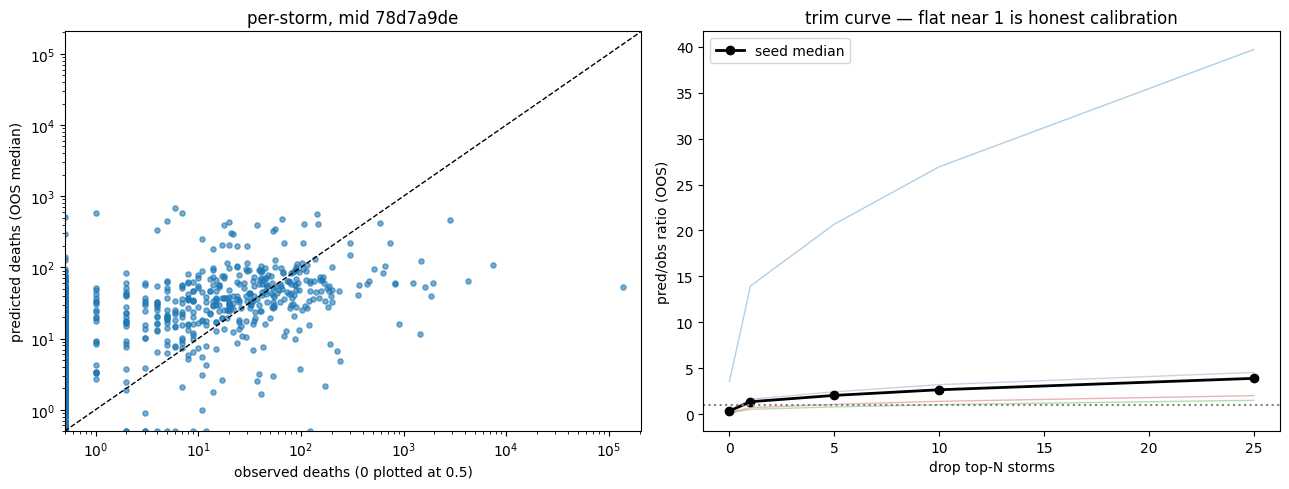

In [17]:
frames = load_pred_frames(WINNER_MID)
oos_tags = sorted(t for t in frames if t.startswith('oos_seed'))

per_seed_storm = [(_per_storm(frames[t]).assign(seed=t)) for t in oos_tags]
storm = (pd.concat(per_seed_storm)
         .groupby('storm_id', as_index=False)
         .agg(obs_d=('obs_d', 'first'), pred=('pred', 'median')))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
nz = storm[(storm.obs_d > 0) | (storm.pred > 0)]
ax.scatter(nz['obs_d'].clip(lower=0.5), nz['pred'].clip(lower=0.5), s=14, alpha=0.6)
lim = [0.5, max(nz['obs_d'].max(), nz['pred'].max()) * 1.5]
ax.plot(lim, lim, 'k--', lw=1)
ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim,
       xlabel='observed deaths (0 plotted at 0.5)',
       ylabel='predicted deaths (OOS median)',
       title=f'per-storm, mid {WINNER_MID[:8]}')

ax = axes[1]
w = pd.DataFrame(trim_per_seed(WINNER_MID))
woos = w[w.fold_tag != 'insample']
for t, grp in woos.groupby('fold_tag'):
    ax.plot(grp['drop_top_n'], grp['ratio'], alpha=0.35, lw=1)
med = woos.groupby('drop_top_n')['ratio'].median()
ax.plot(med.index, med.values, 'k-o', lw=2, label='seed median')
ax.axhline(1.0, color='grey', ls=':')
ax.set(xlabel='drop top-N storms', ylabel='pred/obs ratio (OOS)',
       title='trim curve — flat near 1 is honest calibration')
ax.legend()
plt.tight_layout()
plt.show()

## Next steps

- v1985 clone (flat prediction layout: swap the index builder for a flat scandir).
- Cross-vintage universal: match by CONFIG_COLS, never mid.
- Draws-wiring check for cens/trunc/gpd_cens families before any such winner ships.